# Train a compact binary RF tutorial

Run with **Python (crystal_seg)** from `training/` or the project root. Use eight images containing both groups: raw labels **11/12 → group 1**, **31/32 → group 3**. Inspect every image's GMM components before editing the manual-label dictionary. Label **0** or **None** means ignore. Figures stay inline in this notebook; arrays and models are saved under `output/tutorial_mixed_groups_compact_001/`.

The appendix contains class extracts, held-out prediction comparisons and feature importance. No accuracy scores are calculated or displayed.

## 1. Paths and settings

In [1]:
from pathlib import Path
import sys, json, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): WORK_DIR /= "training"
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from training/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))
from crystal_preprocessing import preprocess_image
from crystal_features import calculate_image_features, FEATURE_NAMES, FEATURE_CALCULATION
from crystal_gmm import fit_image_gmm

# Match the implementation tutorial's current illustrative image.
IMAGE_PATH = PROJECT_ROOT / "data/mag500/old/pl09/20260806_140719.jpg"
TRAINING_DIR = PROJECT_ROOT / "data/mag500/training"
REFERENCE_PATH = WORK_DIR / "data/models/color_reference.pkl"
OUTPUT_DIR = WORK_DIR / "output/tutorial_mixed_groups_compact_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {"crop": {"top": 60, "bottom": 100, "left": 60, "right": 100}, "n_segments": 300, "compactness": 10.0}
CLASS_IDS = [1, 3]
LABEL_TO_CLASS = {11: 1, 12: 1, 31: 3, 32: 3}  # Preserve raw annotations; train one binary parent-group RF.
GMM_PROBABILITY_CUT = .70
reference = np.asarray(joblib.load(REFERENCE_PATH)["reference_mean"], dtype=np.float64)
print(f"Example image: {IMAGE_PATH}\nTraining folder: {TRAINING_DIR}\nOutputs: {OUTPUT_DIR}")
from sklearn.ensemble import RandomForestClassifier
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=2, class_weight="balanced", random_state=0, n_jobs=1)
APPENDIX_DIR = OUTPUT_DIR / "appendix"
APPENDIX_DIR.mkdir(exist_ok=True)

Example image: /home/kmanabe2403/dune/data/mag500/old/pl09/20260806_140719.jpg
Training folder: /home/kmanabe2403/dune/data/mag500/training
Outputs: /home/kmanabe2403/dune/training/output/tutorial_mixed_groups_compact_001


## 2. Crop the example image
Black frames show image edges; red marks the retained region. Images are not resized.

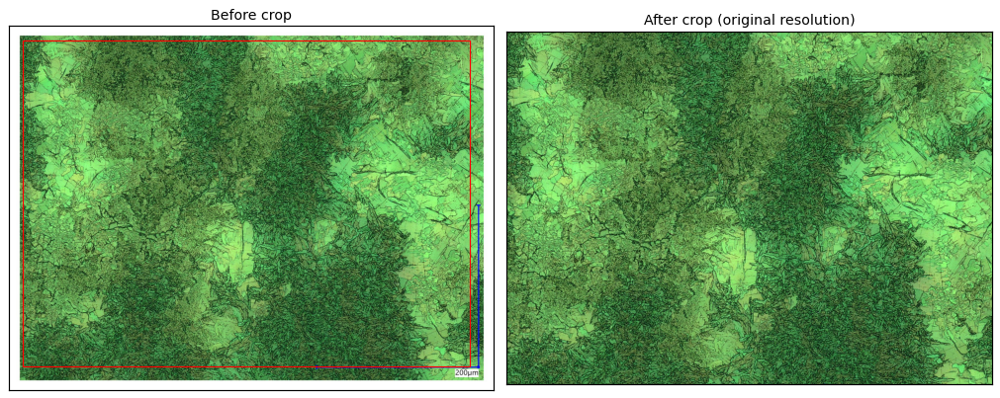

In [2]:
from skimage import io
from matplotlib.patches import Rectangle

original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = CONFIG["crop"]
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"]-.5, crop["top"]-.5), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title("Before crop")
axes[1].imshow(image)
axes[1].set_title("After crop (original resolution)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values(): spine.set(color="black", linewidth=1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=120)
plt.show()
plt.close(fig)
del original

## 3. Superpixels and features
Thin red lines show superpixel boundaries. Use the shared 18 features and fixed-reference color correction.

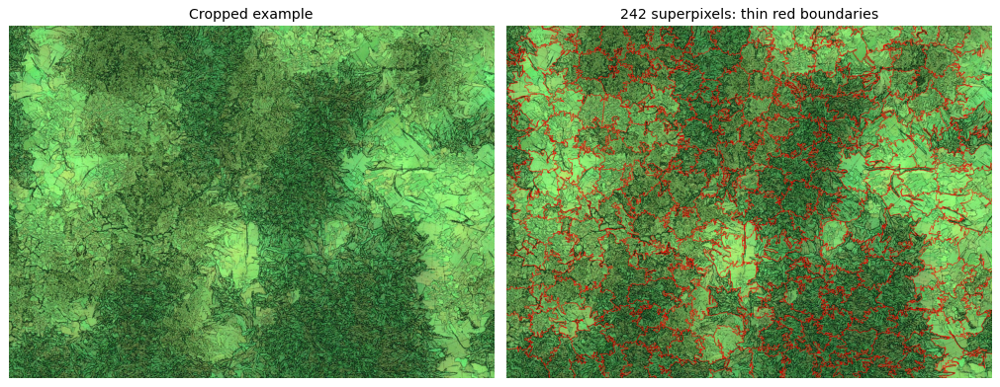

In [3]:
def prepare_image(path, directory):
    preprocess_image(path, directory, CONFIG)
    with np.load(directory / "lab_means.npz") as saved:
        labels, means = saved["labels"], saved["lab_means"]
    correction = reference - means.mean(axis=0)
    corrected = directory / "corrected_lab.npz"
    np.savez(corrected, labels=labels, lab_means=means + correction, correction=correction)
    labels, features = calculate_image_features(directory, corrected)
    feature_path = directory / "features.npz"
    np.savez(feature_path, labels=labels, features=features, feature_names=FEATURE_NAMES, feature_calculation=FEATURE_CALCULATION)
    return feature_path

from skimage.segmentation import mark_boundaries
EXAMPLE_DIR = OUTPUT_DIR / "example"
example_features = prepare_image(IMAGE_PATH, EXAMPLE_DIR)
segments = np.load(EXAMPLE_DIR / "segments.npy")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Cropped example")
axes[1].imshow(np.clip(mark_boundaries(image, segments, color=(1, 0, 0), mode="inner"), 0, 1))
axes[1].set_title(f"{len(np.unique(segments))} superpixels: thin red boundaries")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_superpixels.png", dpi=120)
plt.show()
plt.close(fig)

## 4. Example GMM
Original image and area fractions above, original-color components below. Component IDs are not manual labels.

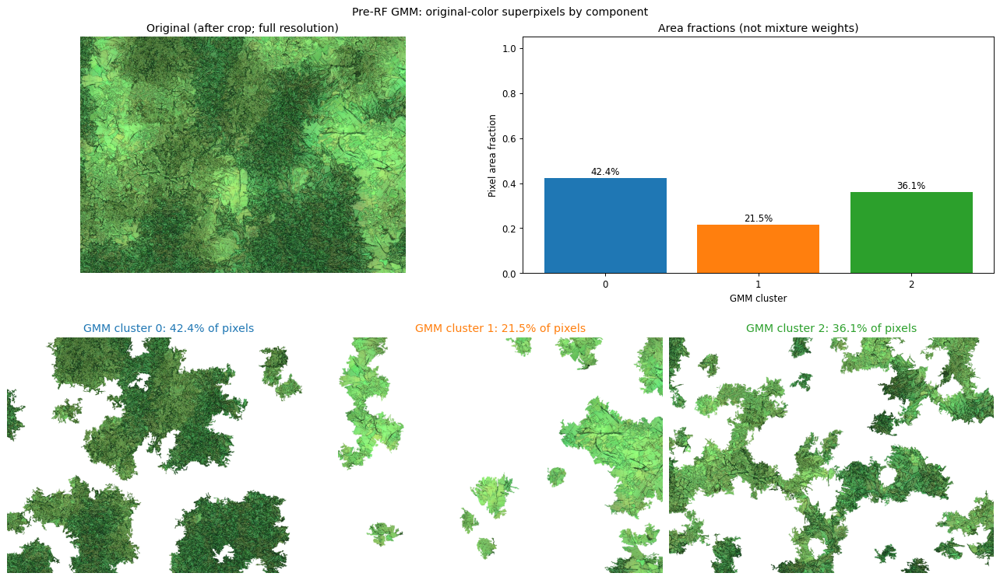

In [4]:
example_gmm = fit_image_gmm(example_features, n_components=3, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
with np.load(example_features) as saved: example_labels = saved["labels"]
cluster_labels = np.full(len(example_labels), -1, dtype=int)
cluster_labels[example_gmm["valid_indices"]] = example_gmm["cluster_labels"]
cluster_map = cluster_labels[np.searchsorted(example_labels, segments)]
colors = plt.cm.tab10(np.arange(3))
area = np.bincount(cluster_map.ravel(), minlength=3) / cluster_map.size
fig = plt.figure(figsize=(15, 9), layout="constrained")
top, bottom = fig.subfigures(2, 1)
original_ax, area_ax = top.subplots(1, 2)
original_ax.imshow(image)
original_ax.set_title("Original (after crop; full resolution)")
original_ax.axis("off")
area_ax.bar(np.arange(3), area, color=colors)
area_ax.set(xlabel="GMM cluster", ylabel="Pixel area fraction", xticks=np.arange(3), ylim=(0, 1.05), title="Area fractions (not mixture weights)")
for k, value in enumerate(area): area_ax.text(k, value + .015, f"{value:.1%}", ha="center")
for k, ax in enumerate(np.atleast_1d(bottom.subplots(1, 3))):
    view = np.full_like(image, 255)
    mask = cluster_map == k
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(f"GMM cluster {k}: {area[k]:.1%} of pixels", color=colors[k])
    ax.axis("off")
fig.suptitle("Pre-RF GMM: original-color superpixels by component")
fig.savefig(OUTPUT_DIR / "03_example_gmm.png", dpi=120)
plt.show()
plt.close(fig)
np.savez_compressed(EXAMPLE_DIR / "gmm.npz", **example_gmm)
del image, segments, view

## 5. Prepare eight mixed images

Use the same selected images and archived GMM component counts. Save one image at a time to limit memory use. Only progress messages are printed.

In [5]:
manifest = pd.read_csv(WORK_DIR / "data/tables/tutorial_images.csv")
assert len(manifest) == manifest.image_hash.nunique() == 8
for row in manifest.itertuples(index=False):
    path = PROJECT_ROOT / row.path
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row.image_hash, f"Source changed: {path}"
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    feature_path = prepare_image(path, directory)
    result = fit_image_gmm(feature_path, row.n_components, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
    np.savez_compressed(directory / "gmm.npz", **result)
    print(f"{row.image_id+1}/8: {row.name}; {len(result['valid_indices'])} superpixels; {row.n_components} GMM components", flush=True)
    gc.collect()
manifest.to_csv(OUTPUT_DIR / "images.csv", index=False)

1/8: 0053_20260807_103050; 275 superpixels; 3 GMM components
2/8: 20260805_125544; 240 superpixels; 2 GMM components
3/8: 20260805_125625; 251 superpixels; 2 GMM components
4/8: 20260806_143420; 210 superpixels; 2 GMM components
5/8: 20260807_100809; 250 superpixels; 2 GMM components
6/8: 20260807_102830; 270 superpixels; 2 GMM components
7/8: 20260807_124648; 238 superpixels; 3 GMM components
8/8: 20260807_124732; 238 superpixels; 2 GMM components


## 6. Inspect GMM components before labeling

For each image, compare the original with components **GMM 0, 1, ...** on white backgrounds. Inspect all eight figures before editing the next cell. White means outside that component; no confidence cut is applied to these previews.

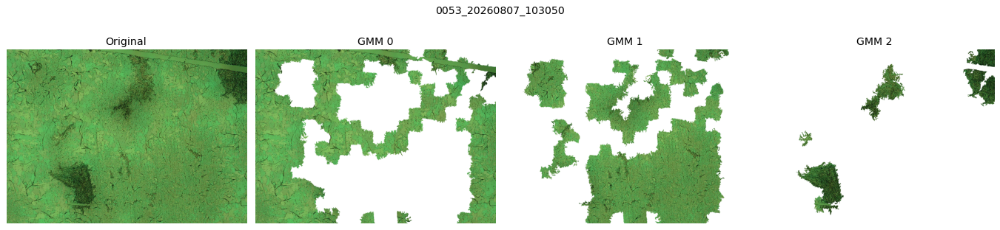

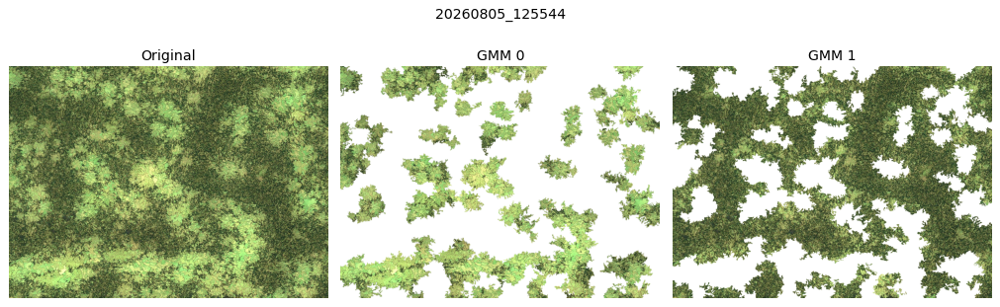

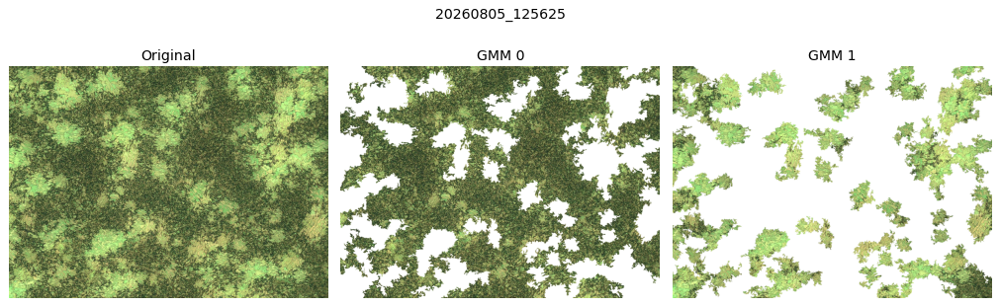

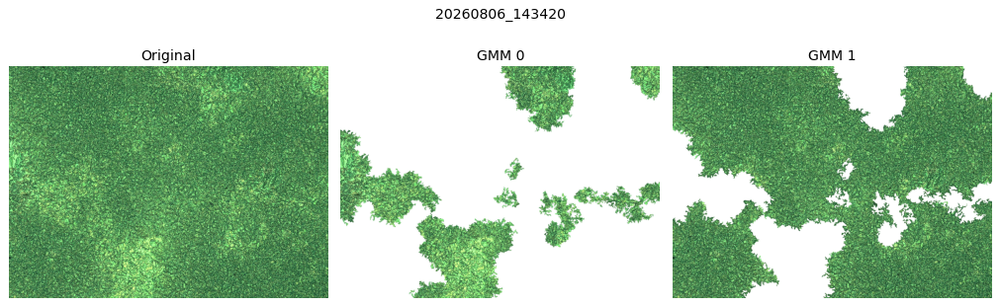

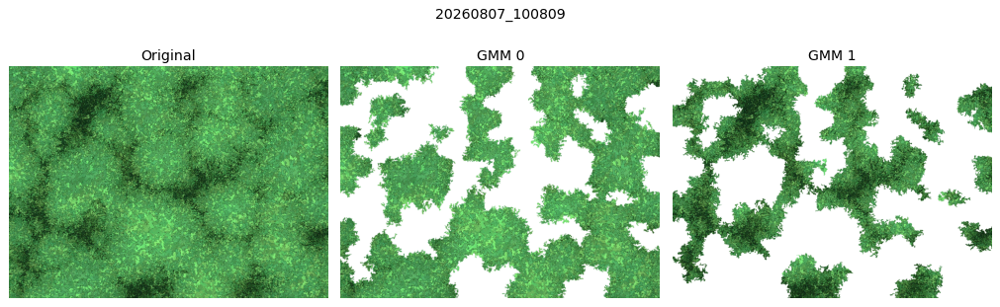

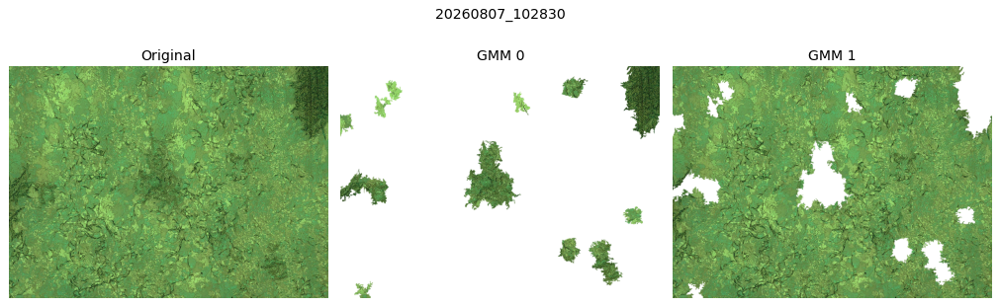

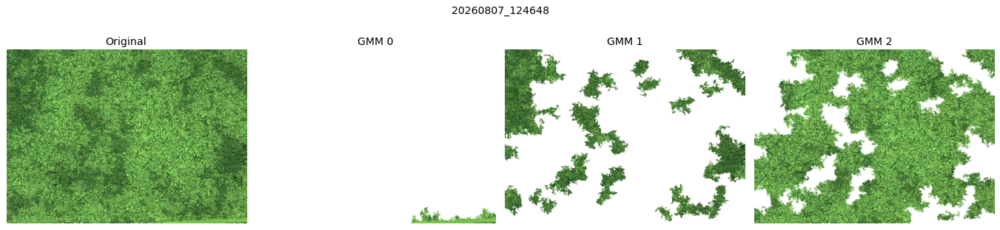

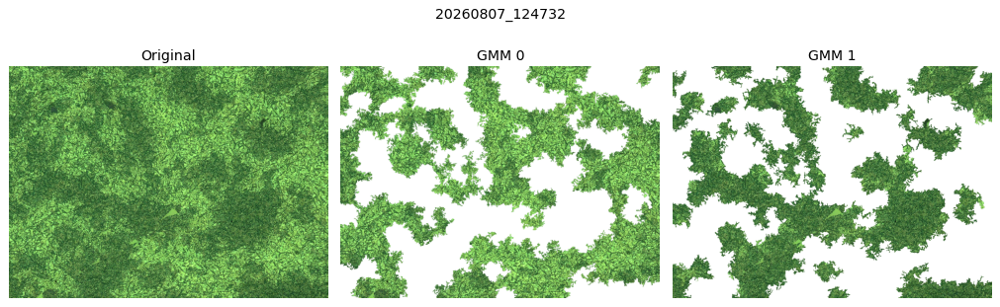

In [6]:
preview_dir = OUTPUT_DIR / "gmm_previews"
preview_dir.mkdir(exist_ok=True)
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
    with np.load(directory / "gmm.npz") as saved:
        groups = np.full(len(saved["labels"]), -1, dtype=int)
        groups[saved["valid_indices"]] = saved["cluster_labels"]
        group_map = groups[np.searchsorted(saved["labels"], segments)]
    fig, axes = plt.subplots(1, row.n_components + 1, figsize=(4 * (row.n_components + 1), 4))
    axes[0].imshow(image)
    axes[0].set_title("Original")
    for cluster, ax in enumerate(axes[1:]):
        view = np.full_like(image, 255)
        view[group_map == cluster] = image[group_map == cluster]
        ax.imshow(view)
        ax.set_title(f"GMM {cluster}")
    for ax in axes: ax.axis("off")
    fig.suptitle(row.name)
    fig.tight_layout()
    fig.savefig(preview_dir / f"image_{row.image_id:04d}.png", dpi=110)
    plt.show()
    plt.close(fig)
    del image, segments, group_map, view

## 7. Enter manual labels

Edit each list in **GMM 0, GMM 1, ... order**, matching the figures above. Use **11 or 12 for group 1**, **31 or 32 for group 3**, and **0 or None to ignore** a component. The existing archived labels are prefilled as editable examples; no RF predictions supply these labels. The `[0,0]` archived subcomponents of image `20260807_124648` are both ignored, so their whole parent component is 0.

This dictionary is the annotation source. Rerunning this cell writes it to `manual_labels.json` and `cluster_labels.csv`; edit here rather than editing the generated CSV. After changes, rerun Cell 8 and the appendix.

In [7]:
MANUAL_LABELS = {
    "0053_20260807_103050": [31, 31, 12],
    "20260805_125544": [31, 11],
    "20260805_125625": [11, 31],
    "20260806_143420": [32, 11],
    "20260807_100809": [32, 11],
    "20260807_102830": [11, 32],
    "20260807_124648": [0, 11, 32],
    "20260807_124732": [32, 11],
}
annotation_rows = []
if set(MANUAL_LABELS) != set(manifest.name): raise ValueError("Provide exactly one label list per selected image.")
for row in manifest.itertuples(index=False):
    values = MANUAL_LABELS[row.name]
    if len(values) != row.n_components: raise ValueError(f"{row.name}: expected {row.n_components} labels in GMM order.")
    if any(v is not None and (not isinstance(v, int) or v not in {0, *LABEL_TO_CLASS}) for v in values):
        raise ValueError("Use 11, 12, 31, 32, 0 or None.")
    for cluster, value in enumerate(values):
        annotation_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": cluster,
                                "manual_label": value, "parent_group": LABEL_TO_CLASS.get(value)})
annotations = pd.DataFrame(annotation_rows)
annotations.to_csv(OUTPUT_DIR / "cluster_labels.csv", index=False)
(OUTPUT_DIR / "manual_labels.json").write_text(json.dumps(MANUAL_LABELS, indent=2) + "\n")
print("Manual labels saved. Run the next cell to fit the RF.")

Manual labels saved. Run the next cell to fit the RF.


## 8. Build the supervised dataset and train the RF

Use annotated superpixels with GMM probability ≥ 0.70. Keep raw labels and mapped parent groups in the saved table. Save the final eight-image model; the appendix fits separate six-image models for held-out visual comparisons.

In [8]:
frames = []
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    with np.load(directory / "features.npz") as saved: features = saved["features"]
    with np.load(directory / "gmm.npz") as saved:
        indices, clusters, probability = saved["valid_indices"], saved["cluster_labels"], saved["max_probability"]
    frame = pd.DataFrame(features[indices], columns=FEATURE_NAMES)
    frame["image_id"], frame["superpixel_index"] = row.image_id, indices
    frame["gmm_cluster"], frame["gmm_probability"] = clusters, probability
    frame["source_manual_label"] = [MANUAL_LABELS[row.name][k] for k in clusters]
    frame["manual_label"] = frame.source_manual_label.map(LABEL_TO_CLASS)
    frames.append(frame)
all_superpixels = pd.concat(frames, ignore_index=True)
dataset = all_superpixels[all_superpixels.manual_label.notna() & (all_superpixels.gmm_probability >= GMM_PROBABILITY_CUT)].copy()
dataset["manual_label"] = dataset.manual_label.astype(int)
if set(dataset.manual_label) != set(CLASS_IDS): raise ValueError("Annotate both groups before training.")
dataset.to_csv(OUTPUT_DIR / "rf_training.csv", index=False)
final_rf = RandomForestClassifier(**RF_PARAMS).fit(dataset[FEATURE_NAMES], dataset.manual_label)
joblib.dump({"model": final_rf, "feature_names": FEATURE_NAMES, "feature_calculation": FEATURE_CALCULATION,
             "reference_mean": reference, "class_ids": CLASS_IDS, "manual_to_class": LABEL_TO_CLASS,
             "preprocessing": CONFIG, "training_image_hashes": manifest.image_hash.tolist(), "manual_labels": MANUAL_LABELS},
            OUTPUT_DIR / "rf_demo_all8.pkl")
print(f"RF saved: {OUTPUT_DIR / 'rf_demo_all8.pkl'} ({len(dataset):,} labeled superpixels)")

RF saved: /home/kmanabe2403/dune/training/output/tutorial_mixed_groups_compact_001/rf_demo_all8.pkl (1,805 labeled superpixels)


# Appendix

Optional visual checks. Run after the manual-label and RF cells.

## A. Superpixels assigned to each manual class

One original-color extract per image and parent class. Combine all GMM components assigned to that class. Include low-confidence members; white means outside the selected class.

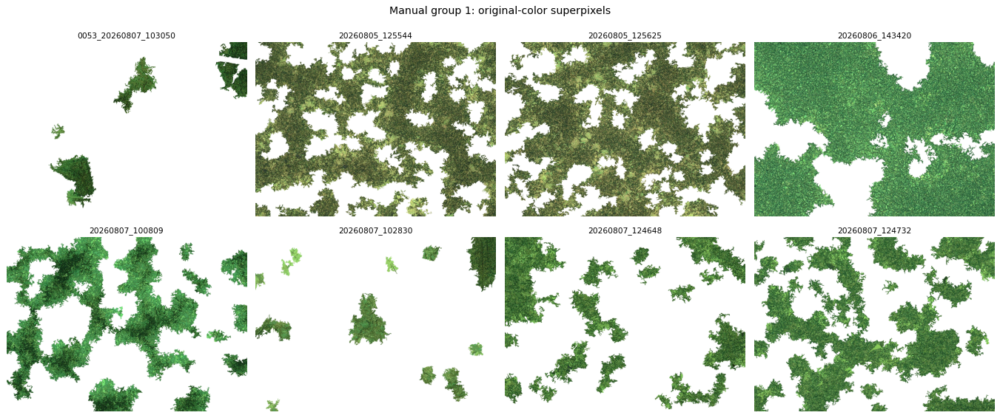

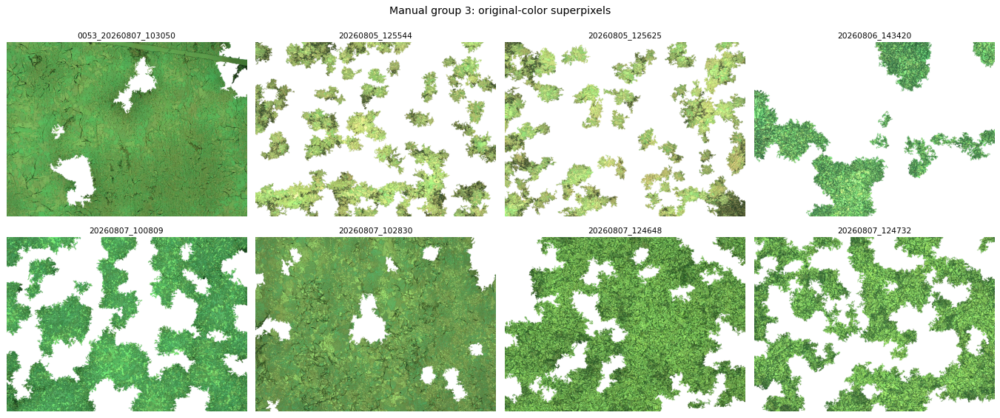

In [9]:
for class_id in CLASS_IDS:
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, row in zip(axes.flat, manifest.itertuples(index=False)):
        directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
        image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
        with np.load(directory / "gmm.npz") as saved:
            chosen = [k for k, v in enumerate(MANUAL_LABELS[row.name]) if LABEL_TO_CLASS.get(v) == class_id]
            members = saved["valid_indices"][np.isin(saved["cluster_labels"], chosen)]
            mask = np.isin(segments, saved["labels"][members])
        view = np.full_like(image, 255)
        view[mask] = image[mask]
        ax.imshow(view)
        ax.set_title(row.name, fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Manual group {class_id}: original-color superpixels")
    fig.tight_layout()
    fig.savefig(APPENDIX_DIR / f"manual_group_{class_id}.png", dpi=130)
    plt.show()
    plt.close(fig)
    del image, segments, mask, view

## B. Original / RF only / RF + GMM vote

Eight figures, one for each image. **Blue = group 1; orange = group 3.** Four fixed image folds fit on six images and predict the other two, so each displayed image is held out once. The final all-eight RF is not used here. Each fold uses the same RF in both prediction modes; GMM voting includes all valid superpixels.

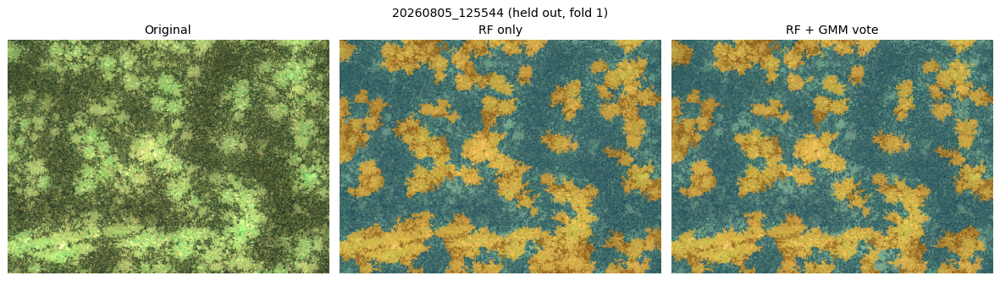

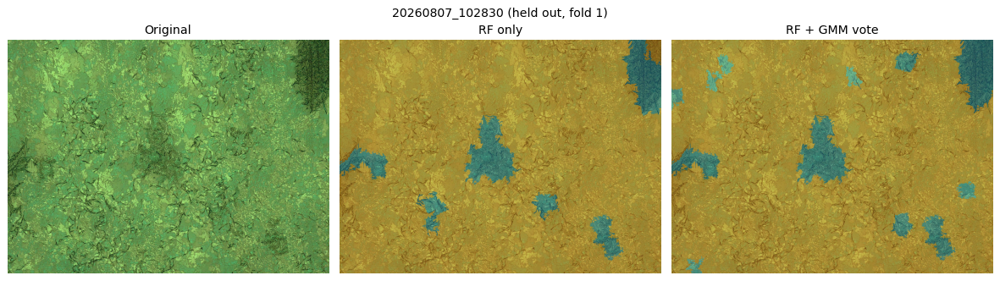

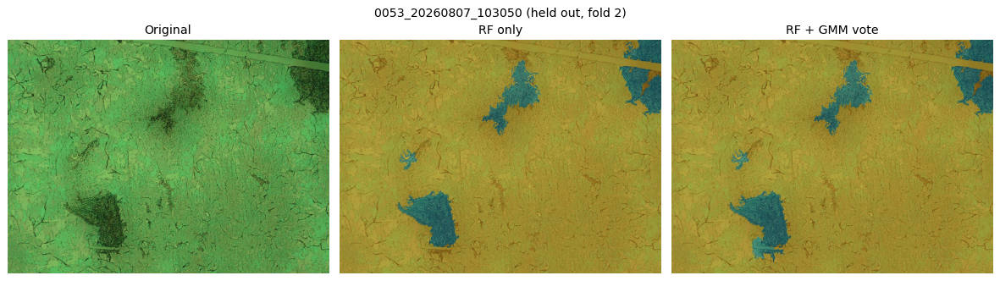

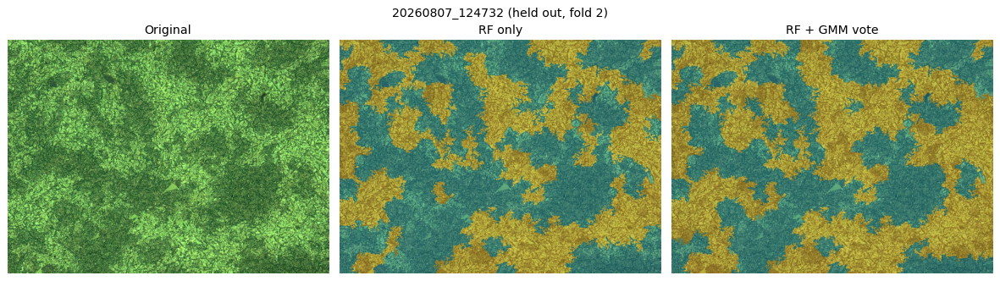

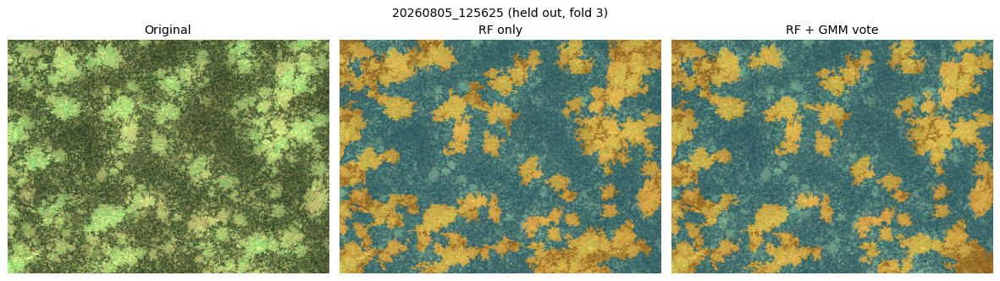

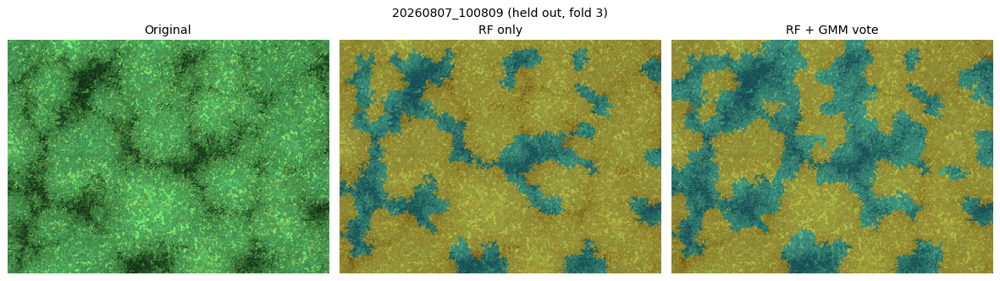

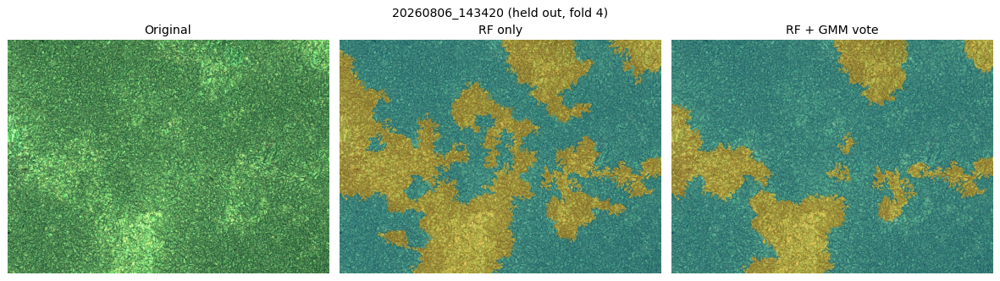

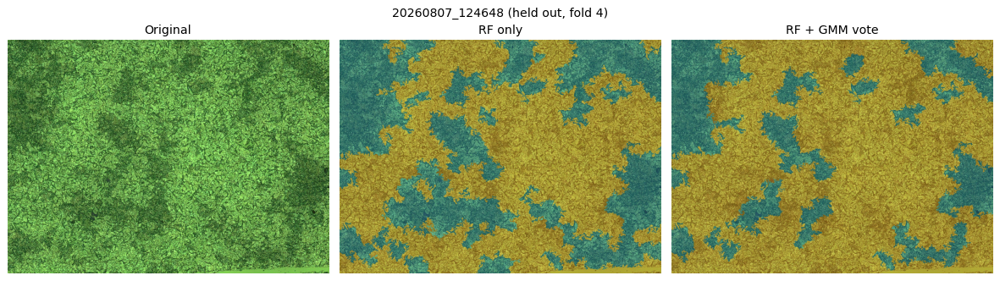

In [10]:
from sklearn.model_selection import KFold
from matplotlib.colors import ListedColormap
from crystal_rf import majority_vote

fold_importances, split_rows = [], []
for fold, (train_pos, test_pos) in enumerate(KFold(4, shuffle=True, random_state=42).split(manifest), 1):
    train_ids, test_ids = manifest.iloc[train_pos].image_id, manifest.iloc[test_pos].image_id
    train = dataset[dataset.image_id.isin(train_ids)]
    if set(train.manual_label) != set(CLASS_IDS): raise ValueError(f"Fold {fold} needs both training classes.")
    assert set(manifest.iloc[train_pos].image_hash).isdisjoint(manifest.iloc[test_pos].image_hash)
    model = RandomForestClassifier(**RF_PARAMS).fit(train[FEATURE_NAMES], train.manual_label)
    fold_importances.append(model.feature_importances_)
    joblib.dump({"model": model, "training_image_ids": train_ids.tolist(), "test_image_ids": test_ids.tolist()},
                APPENDIX_DIR / f"fold_{fold:02d}_rf.pkl")
    for image_id in test_ids:
        row = manifest[manifest.image_id == image_id].iloc[0]
        directory = OUTPUT_DIR / "rf_data" / f"image_{image_id:04d}"
        image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
        with np.load(directory / "features.npz") as saved: features, labels = saved["features"], saved["labels"]
        with np.load(directory / "gmm.npz") as saved: valid, clusters = saved["valid_indices"], saved["cluster_labels"]
        direct = model.predict(pd.DataFrame(features, columns=FEATURE_NAMES))
        voted = direct.copy()
        for cluster in np.unique(clusters):
            members = valid[clusters == cluster]
            voted[members] = int(majority_vote(direct[members])[0])
        np.savez_compressed(APPENDIX_DIR / f"image_{image_id:04d}_predictions.npz", labels=labels, rf_prediction=direct, rf_gmm_prediction=voted)
        split_rows.append({"image_id": image_id, "fold": fold, "name": row["name"]})
        indices = np.searchsorted(labels, segments)
        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        for ax in axes: ax.imshow(image); ax.axis("off")
        axes[0].set_title("Original")
        for ax, values, title in zip(axes[1:], [direct, voted], ["RF only", "RF + GMM vote"]):
            encoded = np.searchsorted(CLASS_IDS, values)
            ax.imshow(encoded[indices], cmap=ListedColormap(["tab:blue", "tab:orange"]), vmin=0, vmax=1, alpha=.4)
            ax.set_title(title)
        fig.suptitle(f"{row['name']} (held out, fold {fold})")
        fig.tight_layout()
        fig.savefig(APPENDIX_DIR / f"comparison_{image_id:04d}.png", dpi=110)
        plt.show()
        plt.close(fig)
        del image, segments, indices
        gc.collect()
pd.DataFrame(split_rows).to_csv(APPENDIX_DIR / "held_out_images.csv", index=False)

## C. Feature importance

Mean impurity-based importance across the four six-image RFs from Appendix B. This describes the models' splits, not causal effects.

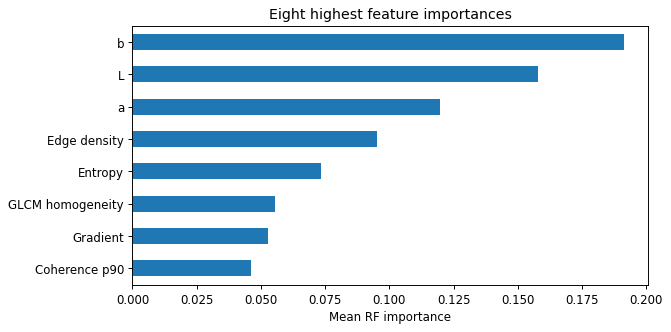

In [11]:
importance = pd.Series(np.mean(fold_importances, axis=0), index=FEATURE_NAMES).sort_values()
importance.rename("mean_importance").to_csv(APPENDIX_DIR / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(8, 4))
importance.tail(8).plot.barh(ax=ax)
ax.set(xlabel="Mean RF importance", title="Eight highest feature importances")
fig.tight_layout()
fig.savefig(APPENDIX_DIR / "feature_importance.png", dpi=120)
plt.show()
plt.close(fig)